# Controlled two-task paradigm: A → B → A

**Question.** When a one-module network learns task B after task A, how does A's
geometry change? How much of the change is set by the task relation (Hamming(A, B),
input change s_f) and how much by the learner (richness γ₀)? What does relearning A
recover?

**Slot.** `docs/26` Part B, two-task paradigm: the controlled experiment that comes
before the stream (Kati, 2026-11-06). It is part of the `docs/24` §4 core.

**Pre-commit.** None yet. This notebook establishes the instrument (sections 1–4) and
reports **observations at n = 3, not claims**. Readings are not named, so nothing here
is read as a finding.

**Self-contained.** Everything lives in `aba_lib.py` next to this notebook: the
generator, the 1M network, training, NTK, and a vendored copy of GLUE. Section 3
asserts that the GLUE copy matches `src.glue.core`.

## 1. Config

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[_v] = "1"          # before numpy is imported anywhere in this kernel

QUICK = True        # QUICK: M=50, n_t=50, n=3.  Full: M=150, n_t=200, n=8.
RUN_GRID = True     # the QUICK grid (54 design arms + 2 fresh-noise identity arms)
WORKERS = 6         # spawned workers; capped at 6 for laptop memory

import sys, time, json, math
from pathlib import Path
here = Path.cwd().resolve()
REPO = next(p for p in [here, *here.parents] if (p / ".git").exists())
sys.path[:0] = [str(REPO / "notebooks" / "core"), str(REPO)]

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import aba_lib as L

cfg = L.ABAConfig.make(QUICK)
STAMP = L.git_stamp()

def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

md_table(["parameter", "value"], [[k, v] for k, v in vars(cfg).items()])
print(f"aba_lib hash {L.lib_hash()}   commit {STAMP['commit']}   dirty {STAMP['dirty']}")
print(f"numpy {np.__version__}   python {sys.version.split()[0]}   cache {L.cache_path(cfg).relative_to(REPO)}")

| parameter | value |
|---|---|
| quick | True |
| P | 16 |
| d | 150 |
| D | 4 |
| R | 1.0 |
| M | 50 |
| N | 300 |
| lr0 | 5.0 |
| n_base | 64 |
| target_loss | 0.05 |
| max_steps | 20000 |
| record_every | 25 |
| n_t | 50 |
| center_policy | all |
| ntk_per_manifold | 20 |
| probe_hamming | 4 |
| gammas | (0.1, 10.0) |
| hammings | (0, 4, 8) |
| s_fs | (1.0, 0.9, 0.1) |
| n_seeds | 3 |

aba_lib hash 0cb635a8b44814ad   commit 52f5567e512f   dirty True
numpy 2.4.6   python 3.11.9   cache results\aba\QUICK_0cb635a8b44814ad.jsonl


In [2]:
# Palette: reference categorical order (blue, orange, aqua); diverging blue ↔ orange through a neutral grey.
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
GAMMA_COL = {cfg.gammas[0]: BLUE, cfg.gammas[1]: ORANGE}
LABEL_COL = {1: BLUE, -1: ORANGE}
from matplotlib.colors import LinearSegmentedColormap
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2.0, "font.size": 9})
CHECKS = []   # (check, PASS/FAIL, detail): validation checks, kept apart from observations
def check(name, ok, detail=""):
    CHECKS.append((name, "PASS" if ok else "**FAIL**", detail))
    print(("PASS " if ok else "FAIL ") + name + (f"  ({detail})" if detail else ""))

## 2. Manifolds

Seed 0 is shown. A and y_A are shared by every cell and both γ₀. B is A's
arrangement with centres redrawn at ρ = s_f (axes and shapes held), labelled by a
dichotomy at the stated Hamming distance from y_A. **At s_f = 1.0, B's points are
A's points exactly.**

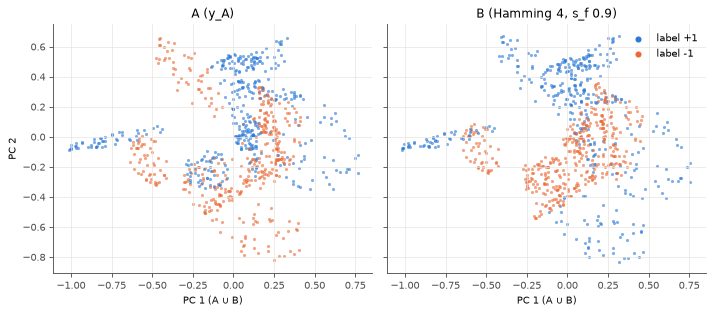

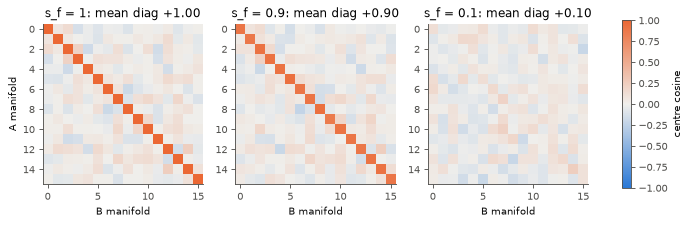

In [3]:
base = L.seed_base(cfg, 0)
H_SHOW, SF_SHOW = 4, 0.9
B_show = L.b_arrangement(cfg, base, SF_SHOW)
pts = np.concatenate([base.A.points.reshape(-1, cfg.d), B_show.points.reshape(-1, cfg.d)])
mu = pts.mean(0); _, _, Vt = np.linalg.svd(pts - mu, full_matrices=False); basis = Vt[:2]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, arr, y, title in [(axes[0], base.A, base.y_A, "A (y_A)"),
                          (axes[1], B_show, base.y_Bs[H_SHOW], f"B (Hamming {H_SHOW}, s_f {SF_SHOW})")]:
    for m in range(cfg.P):
        Z = (arr.points[m] - mu) @ basis.T
        ax.scatter(Z[:, 0], Z[:, 1], s=8, color=LABEL_COL[int(y[m])], alpha=0.6, linewidths=0)
    ax.set_title(title); ax.set_xlabel("PC 1 (A ∪ B)")
axes[0].set_ylabel("PC 2")
for lab, col in LABEL_COL.items():
    axes[1].scatter([], [], color=col, s=20, label=f"label {lab:+d}")
axes[1].legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.4))
for ax, sf in zip(axes, cfg.s_fs):
    C = L.centre_cosines(base.A.centers, L.b_arrangement(cfg, base, sf).centers)
    im = ax.imshow(C, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_title(f"s_f = {sf:g}: mean diag {np.mean(np.diag(C)):+.2f}"); ax.set_xlabel("B manifold"); ax.grid(False)
axes[0].set_ylabel("A manifold"); fig.colorbar(im, ax=axes, shrink=0.8, label="centre cosine"); plt.show()

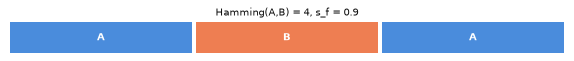

label relations, seed 0 (signed s_r = 1 − 2·Hamming/P):


| Hamming(A,B) | s_r(y_A, y_B) | s_r(y*, y_A) | s_r(y*, y_B) |
|---|---|---|---|
| 0 | +1.000 | +0.500 | +0.500 |
| 4 | +0.500 | +0.500 | +0.000 |
| 8 | +0.000 | +0.500 | +0.250 |

In [4]:
def stream_strip(ax, h, sf, widths=(1, 1, 1)):
    x = 0
    for (lab, col), w in zip([("A", BLUE), ("B", ORANGE), ("A", BLUE)], widths):
        ax.add_patch(plt.Rectangle((x + 0.01, 0), w - 0.02, 1, color=col, alpha=0.85, linewidth=0))
        ax.text(x + w / 2, 0.5, lab, ha="center", va="center", color="white", fontsize=9, weight="bold")
        x += w
    ax.set_xlim(0, x); ax.set_ylim(0, 1); ax.axis("off")
    ax.set_title(f"Hamming(A,B) = {h}, s_f = {sf:g}", fontsize=9, color=INK)

fig, ax = plt.subplots(figsize=(9, 0.5)); stream_strip(ax, H_SHOW, SF_SHOW); plt.show()
print("label relations, seed 0 (signed s_r = 1 − 2·Hamming/P):")
md_table(["Hamming(A,B)", "s_r(y_A, y_B)", "s_r(y*, y_A)", "s_r(y*, y_B)"],
         [[h, f"{L.s_r(base.y_A, yb):+.3f}", f"{L.s_r(base.y_star, base.y_A):+.3f}",
           f"{L.s_r(base.y_star, yb):+.3f}"] for h, yb in base.y_Bs.items()])

## 3. Estimator validation (must pass)

In [5]:
# (a) Vendored GLUE equals src.glue.core on one example, when src imports.
try:
    from src.glue.core import glue_measures as src_glue, Ensemble as SrcEnsemble
except Exception as e:  # noqa: BLE001
    src_glue = None; print("src not importable, comparison skipped:", e)
if src_glue is not None:
    mans = L.as_manifolds(base.A.points)
    y = base.y_A.astype(float)
    a = L.glue_measures(mans, np.random.default_rng(11), n_t=20, ensemble=L.Ensemble("retained", y)).to_dict()
    b = src_glue(mans, np.random.default_rng(11), n_t=20, ensemble=SrcEnsemble("retained", y)).to_dict()
    diff = max(abs(a[k] - b[k]) for k in a if isinstance(a[k], float))
    assert diff == 0.0, f"vendored GLUE differs from src.glue.core by {diff}"
    check("vendored GLUE == src.glue.core (retained y_A, input manifolds)", True, f"max |diff| = {diff:g}")

PASS vendored GLUE == src.glue.core (retained y_A, input manifolds)  (max |diff| = 0)


In [6]:
# (b) Identity residual and (c) capacity falls with R and with D, on input manifolds.
rows, alphas_R, alphas_D, resid = [], [], [], []
for R in (0.5, 1.0, 2.0):
    arr = L.make_arrangement(cfg.P, cfg.d, cfg.D, R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_R.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={R}, D={cfg.D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
for D in (2, 4, 8):
    arr = L.make_arrangement(cfg.P, cfg.d, D, cfg.R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_D.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={cfg.R}, D={D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
md_table(["input manifolds", "α (retained y_A)", "identity residual"], rows)
check("identity residual ≈ 0", max(resid) < 1e-10, f"max {max(resid):.1e}")
check("capacity falls as R grows (0.5 → 1 → 2)", bool(np.all(np.diff(alphas_R) < 0)), str([round(a, 4) for a in alphas_R]))
check("capacity falls as D grows (2 → 4 → 8)", bool(np.all(np.diff(alphas_D) < 0)), str([round(a, 4) for a in alphas_D]))

| input manifolds | α (retained y_A) | identity residual |
|---|---|---|
| R=0.5, D=4 | 0.7438 | 0.0e+00 |
| R=1.0, D=4 | 0.4552 | 1.2e-16 |
| R=2.0, D=4 | 0.3129 | 1.8e-16 |
| R=1.0, D=2 | 0.6495 | 1.7e-16 |
| R=1.0, D=4 | 0.4552 | 1.2e-16 |
| R=1.0, D=8 | 0.3402 | 1.6e-16 |

PASS identity residual ≈ 0  (max 1.8e-16)
PASS capacity falls as R grows (0.5 → 1 → 2)  ([0.7438, 0.4552, 0.3129])
PASS capacity falls as D grows (2 → 4 → 8)  ([0.6495, 0.4552, 0.3402])


In [7]:
# (d) Noise floor: SD of log α over K estimator seeds, on the init representation (identical across γ0).
K_FLOOR = 6
net0 = L.OneModuleNet(base.W0, 1.0, cfg)
P_, M_, d_ = base.A.points.shape
Hrep = net0.hidden(base.A.points.reshape(-1, d_)).reshape(P_, M_, -1)
logs = [math.log(L.capacity(L.as_manifolds(Hrep), base.y_A, cfg, [L.SALT, 0, 1000 + k])["alpha"]) for k in range(K_FLOOR)]
FLOOR_INIT = float(np.std(logs, ddof=1))
print(f"INIT floor (reference only; hidden representation at initialisation, identical across γ0): "
      f"SD(log α) over {K_FLOOR} estimator seeds = {FLOOR_INIT:.4f}  (n_t = {cfg.n_t})")
print("Effects are resolved against the per-γ0 floors on the TRAINED representation (section 4).")

INIT floor (reference only; hidden representation at initialisation, identical across γ0): SD(log α) over 6 estimator seeds = 0.0367  (n_t = 50)
Effects are resolved against the per-γ0 floors on the TRAINED representation (section 4).


## 4. Network validation (must pass)

In [8]:
nets = {g: L.OneModuleNet(base.W0, g, cfg) for g in cfg.gammas}
XA, yA = L.flatten(base.A.points, base.y_A)
check("initial loss = 0.5 for every γ0", all(n.loss(XA, yA) == 0.5 for n in nets.values()),
      str({g: n.loss(XA, yA) for g, n in nets.items()}))
check("hidden init identical across γ0 (bitwise)", np.array_equal(nets[cfg.gammas[0]].W, nets[cfg.gammas[1]].W))
probe = np.concatenate([base.A.points[m, base.ntk_idx[m]] for m in range(cfg.P)])
_, KW0 = nets[cfg.gammas[0]].ntk_blocks(probe)
check("K_W(0) = 0 (readout starts at 0)", float(np.abs(KW0).max()) == 0.0)
tmp = L.OneModuleNet(base.W0, 1.0, cfg); tmp.u = np.random.default_rng(3).standard_normal(cfg.N)
fd = L.ntk_fd_check(tmp, probe[:3], np.random.default_rng(4))
check("analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference",
      fd["K_vs_JJt_rel"] < 1e-12 and fd["Jdelta_vs_fd_rel"] < 1e-5, str({k: f"{v:.1e}" for k, v in fd.items()}))

PASS initial loss = 0.5 for every γ0  ({0.1: 0.5, 10.0: 0.5})
PASS hidden init identical across γ0 (bitwise)
PASS K_W(0) = 0 (readout starts at 0)
PASS analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference  ({'K_vs_JJt_rel': '3.4e-16', 'Jdelta_vs_fd_rel': '5.9e-08'})


In [9]:
# Lazy/rich separation after A, and reaching the target within budget, for every seed and γ0.
sep_rows, sep, budget_ok = [], {}, []
for seed in range(cfg.n_seeds):
    b = L.seed_base(cfg, seed)
    X, y = L.flatten(b.A.points, b.y_A)
    pr = np.concatenate([b.A.points[m, b.ntk_idx[m]] for m in range(cfg.P)])
    yp = np.repeat(b.y_A.astype(float), b.ntk_idx.shape[1])
    for g in cfg.gammas:
        n = L.OneModuleNet(b.W0, g, cfg); Ku0, KW0 = n.ntk_blocks(pr)
        t = L.train_to_criterion(n, X, y, cfg)
        budget_ok.append((seed, g, t["status"], t["steps"]))
        sep[(seed, g)] = L.richness_snapshot(n, Ku0 + KW0, Ku0, pr, yp, pr, yp)
display(Markdown("**NTK change after training on A: absolute values, not ratios.** All three are "
                  "‖·‖_F / ‖K(0)‖_F on A's fixed probe set; K(0) = K_u(0) because K_W(0) = 0. "
                  "ΔK_W is the hidden-weight block grown from zero; ΔK full = ‖ΔK_u + K_W‖."))
NTK_KEYS = [("dK_full", "ΔK full"), ("dK_u", "ΔK_u"), ("dK_W", "ΔK_W"), ("weight_change", "weight change")]
rows = []
for g in cfg.gammas:
    for seed in range(cfg.n_seeds):
        rows.append([f"{g:g}", seed] + [f"{sep[(seed, g)][k]:.4g}" for k, _ in NTK_KEYS])
    rows.append([f"**{g:g}**", "**mean**"] + [f"**{np.mean([sep[(s, g)][k] for s in range(cfg.n_seeds)]):.4g}**" for k, _ in NTK_KEYS])
md_table(["γ0", "seed"] + [lab for _, lab in NTK_KEYS], rows)
for k in ("weight_change", "dK_u", "dK_full"):
    check(f"rich > lazy after A in {k}, every seed",
          all(sep[(s, cfg.gammas[1])][k] > sep[(s, cfg.gammas[0])][k] for s in range(cfg.n_seeds)),
          "direction only; any ratio threshold is Kati's")
md_table(["seed", "γ0", "status", "steps on A"], [[s, f"{g:g}", st, n] for s, g, st, n in budget_ok])
check(f"every γ0 reaches loss {cfg.target_loss} within {cfg.max_steps} steps at lr0 = {cfg.lr0}",
      all(st == "converged" for _, _, st, _ in budget_ok), "a failure is reported, never re-pinned")

**NTK change after training on A: absolute values, not ratios.** All three are ‖·‖_F / ‖K(0)‖_F on A's fixed probe set; K(0) = K_u(0) because K_W(0) = 0. ΔK_W is the hidden-weight block grown from zero; ΔK full = ‖ΔK_u + K_W‖.

| γ0 | seed | ΔK full | ΔK_u | ΔK_W | weight change |
|---|---|---|---|---|---|
| 0.1 | 0 | 0.1824 | 0.04491 | 0.1589 | 0.0186 |
| 0.1 | 1 | 0.1842 | 0.04813 | 0.1592 | 0.01945 |
| 0.1 | 2 | 0.2037 | 0.04291 | 0.1832 | 0.02183 |
| **0.1** | **mean** | **0.1901** | **0.04532** | **0.1671** | **0.01996** |
| 10 | 0 | 33.44 | 8.055 | 29.42 | 0.598 |
| 10 | 1 | 32.19 | 8.277 | 27.98 | 0.6013 |
| 10 | 2 | 34.98 | 7.099 | 31.74 | 0.6447 |
| **10** | **mean** | **33.53** | **7.811** | **29.71** | **0.6146** |

PASS rich > lazy after A in weight_change, every seed  (direction only; any ratio threshold is Kati's)
PASS rich > lazy after A in dK_u, every seed  (direction only; any ratio threshold is Kati's)
PASS rich > lazy after A in dK_full, every seed  (direction only; any ratio threshold is Kati's)


| seed | γ0 | status | steps on A |
|---|---|---|---|
| 0 | 0.1 | converged | 1610 |
| 0 | 10 | converged | 45 |
| 1 | 0.1 | converged | 1660 |
| 1 | 10 | converged | 45 |
| 2 | 0.1 | converged | 1935 |
| 2 | 10 | converged | 52 |

PASS every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0  (a failure is reported, never re-pinned)


In [10]:
# Noise floor per γ0 on the hidden representation AFTER training on A (seed 0, K estimator seeds).
FLOORS = {g: L.trained_floor(cfg, g, seed=0, K=K_FLOOR) for g in cfg.gammas}
md_table(["γ0", "floor SD(log α_A), trained", "K", "n_t", "mean log α_A after A"],
         [[f"{g:g}", f"{f['floor']:.4f}", f["K"], f["n_t"], f"{f['mean_log_alpha']:+.3f}"] for g, f in FLOORS.items()]
         + [["init (reference)", f"{FLOOR_INIT:.4f}", K_FLOOR, cfg.n_t, ""]])
T975 = {2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306}   # t quantiles, df = n − 1 ≥ 2

def resolve(values, floor):
    # docs/26 A4: resolved iff the 95% t-interval over unique draws excludes 0 AND |mean| ≥ 2 floors.
    v = np.asarray(values, float); n = v.size; m = float(v.mean())
    if n < 2: return {"mean": m, "lo": float("nan"), "hi": float("nan"), "n": n, "resolved": False, "sign": 0}
    h = T975.get(n - 1, 1.96) * float(v.std(ddof=1)) / math.sqrt(n)
    res = (m - h > 0 or m + h < 0) and abs(m) >= 2 * floor
    return {"mean": m, "lo": m - h, "hi": m + h, "n": n, "resolved": bool(res), "sign": int(np.sign(m)) if res else 0}

| γ0 | floor SD(log α_A), trained | K | n_t | mean log α_A after A |
|---|---|---|---|---|
| 0.1 | 0.0448 | 6 | 50 | -0.804 |
| 10 | 0.0829 | 6 | 50 | +1.103 |
| init (reference) | 0.0367 | 6 | 50 |  |

## Expectations (written before the grid)

These are directions from earlier signal, not thresholds. They were written on
2026-11-08 before any grid arm ran. After the run, each reading quotes them verbatim
and marks it **held**, **not held**, or **unresolved at floor**.

1. forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1;
2. at γ0 = 10, the utility channel carries most of Δlog α_A;
3. Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain);
4. Hamming 4 and 8 are similar (cliff, not dose);
5. K_u change separates γ0 more cleanly than the full NTK change.

**How each is read.** This is fixed before the run.

**Measure.** Δlog α_A means A's retained capacity from the end of A to the end
of B (`backward.A1_to_B`).

**Resolution rule.** "Resolved" means the 95% t-interval over the n unique draws
excludes 0 **and** |mean| ≥ 2 floors. The floor is the per-γ0 trained-representation
floor. For contrasts across γ0, the floor is the larger of the two.

**Rules per expectation:**

| # | statistic | held | not held | unresolved |
|---|---|---|---|---|
| 1 | per s_f, paired per seed: d = Δlog α_A(γ0=10) − Δlog α_A(γ0=0.1) at Hamming 8 | d resolved < 0 | d resolved > 0 | otherwise |
| 2 | at γ0 = 10, per cell with Hamming ∈ {4, 8} and per (Hamming 0, s_f ∈ {0.9, 0.1}): utility fraction = mean utility / mean total | total resolved and fraction > 0.5 | total resolved and fraction ≤ 0.5 | total unresolved |
| 3 | per γ0: Δlog α_A at Hamming 0, s_f 0.9 | resolved > 0 | resolved < 0 | otherwise |
| 4 | per (γ0, s_f), paired per seed: d = Δlog α_A(Hamming 8) − Δlog α_A(Hamming 4) | 95% interval of d inside ±2 floors (equivalence) | d resolved (differs) | otherwise |
| 5 | after A, over unique (seed, γ0): separation d′ = (mean log x at γ0=10 − mean log x at γ0=0.1) / pooled SD of log x, for x = ΔK_u and x = ΔK full | d′(ΔK_u) > d′(ΔK full) | d′(ΔK_u) ≤ d′(ΔK full) | not used (no capacity floor applies) |

Expectation 5 also reports the absolute lazy values, which are expected to be ≪ 1.

Stratified readings are not pooled. An expectation that holds in some strata and not
others is reported stratum by stratum.

## 5. Runs

**Timing first.** One QUICK arm runs in a spawned worker before anything else. The arm
is γ₀ = 0.1, Hamming 8, s_f = 0.1: lazy training takes the most steps, so this is
expected to be the slowest cell. The full grid runs only when `RUN_GRID = True`. It
includes the identity control (Hamming 0, s_f 1.0) and a **fresh-noise identity
arm**: same manifolds, ε noise redrawn, seed 0, both γ₀. That arm checks the
"frozen = exact copy" choice. Every arm is checkpointed to `results/aba/`, keyed by
the `aba_lib` hash and the config.

In [11]:
TIMING_SPEC = L.ArmSpec(0, cfg.gammas[0], max(cfg.hammings), min(cfg.s_fs))
t0 = time.perf_counter()
timing_arm = L.run_grid(cfg, [TIMING_SPEC], workers=1)[0]
tm = timing_arm["timing"]
print(f"timing arm {TIMING_SPEC.key}: wall {tm['wall_s']:.1f}s in worker "
      f"(train {tm['train_s']:.1f}s, GLUE {tm['glue_s']:.1f}s, NTK {tm['ntk_s']:.1f}s); "
      f"cell {time.perf_counter() - t0:.1f}s incl. spawn or cache load")
print("steps:", timing_arm["behaviour"]["steps"], " usable:", timing_arm["usable"])

timing arm seed=0,gamma=0.1,H=8,s_f=0.1: wall 85.8s in worker (train 80.3s, GLUE 5.4s, NTK 0.1s); cell 0.3s incl. spawn or cache load
steps: {'A1': 1610, 'B': 1430, 'A2': 369, 'freshB': 1732}  usable: True


In [12]:
if RUN_GRID:
    t0 = time.perf_counter()
    L.run_grid(cfg, L.all_specs(cfg), workers=WORKERS)
    GRID_WALL = time.perf_counter() - t0
    print(f"grid: {len(L.all_specs(cfg))} arms requested, wall {GRID_WALL:.0f}s on {WORKERS} workers")
loaded = L.load_results(cfg)
FRESH = [r for r in loaded if r["spec"].get("noise", "copy") == "fresh"]
arms = [r for r in loaded if r["usable"] and r["spec"].get("noise", "copy") == "copy"]
unusable = [r["key"] for r in loaded if not r["usable"]]
print(f"{len(arms)} usable design arms + {len(FRESH)} fresh-noise arms loaded; unusable: {unusable or 'none'}")
stamps = {(r["stamp"]["commit"], r["stamp"]["dirty"], r["lib_hash"]) for r in loaded}
print("provenance (commit, dirty, lib hash):", stamps)
check("every arm stamped with a clean tree", all(r["stamp"]["dirty"] is False for r in loaded),
      str(sorted({str(s[1]) for s in stamps})))

grid: 56 arms requested, wall 0s on 6 workers
54 usable design arms + 2 fresh-noise arms loaded; unusable: none
provenance (commit, dirty, lib hash): {('52f5567e512f', False, '0cb635a8b44814ad')}
PASS every arm stamped with a clean tree  (['False'])


In [13]:
# Identity control (exact copy) and the fresh-noise identity arm, both read from the grid.
for r in [x for x in arms if x["spec"]["hamming"] == 0 and x["spec"]["s_f"] == 1.0 and x["spec"]["seed"] == 0]:
    st, bw = r["behaviour"]["steps"], r["backward"]
    ok = (st["B"] == 0 and st["A2"] == 0 and r["behaviour"]["forget_B_loss"]["forgetting"] == 0.0
          and all(v == 0.0 for v in bw["A1_to_B"].values()) and all(v == 0.0 for v in bw["A1_to_A2"].values()))
    check(f"identity control (Hamming 0, s_f 1.0, copy), γ0={r['spec']['gamma']:g}: 0 steps on B and A2, zero forgetting, Δlog α_A = 0",
          ok, f"steps {st}")
rows = []
for r in sorted(FRESH, key=lambda x: x["spec"]["gamma"]):
    g = r["spec"]["gamma"]; st = r["behaviour"]["steps"]; d = r["backward"]["A1_to_B"]["total"]
    fl = r["behaviour"]["forget_B_loss"]["forgetting"]
    rows.append([f"{g:g}", st["A1"], st["B"], st["A2"], f"{d:+.5f}", f"{d / FLOORS[g]['floor']:+.3f}",
                 f"{fl:+.2e}", f"{r['behaviour']['first_loss']['B']:.5f}"])
    check(f"fresh-noise identity, γ0={g:g}: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target",
          abs(d) < FLOORS[g]["floor"] and r["behaviour"]["first_loss"]["B"] < 2 * cfg.target_loss,
          f"Δlog α_A = {d:+.5f} ({d / FLOORS[g]['floor']:+.2f} floors), steps on B = {st['B']}")
md_table(["γ0", "steps A1", "steps B", "steps A2", "Δlog α_A (A1→B)", "in floors", "forgetting (test loss)", "zero-shot loss on B"], rows)

PASS identity control (Hamming 0, s_f 1.0, copy), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 1610, 'B': 0, 'A2': 0, 'freshB': 1610})
PASS identity control (Hamming 0, s_f 1.0, copy), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 45, 'B': 0, 'A2': 0, 'freshB': 45})
PASS fresh-noise identity, γ0=0.1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00010 (+0.00 floors), steps on B = 1)
PASS fresh-noise identity, γ0=10: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0)


| γ0 | steps A1 | steps B | steps A2 | Δlog α_A (A1→B) | in floors | forgetting (test loss) | zero-shot loss on B |
|---|---|---|---|---|---|---|---|
| 0.1 | 1610 | 1 | 0 | +0.00010 | +0.002 | -5.90e-05 | 0.05006 |
| 10 | 45 | 0 | 0 | +0.00000 | +0.000 | +0.00e+00 | 0.04693 |

### Per-arm output schema

Every arm must carry each field below, finite. Groups:
- **backward:** Δlog α_A in three channels plus total and residual, at each phase
  (init→A, A→B, B→A, A→ABA).
- **forgetting:** against the running max (accuracy) or running min (loss).
- **forward:** FT_geo with y\* and the signed s_r relations.
- **behaviour:** FT_beh against a fresh learner, savings, raw steps, and zero-shot
  losses.
- **richness:** weight change, r_t, ΔK full, ΔK_u and ΔK_W, NTK–label alignment.
- **geometry:** ρ_c signed and `glue`.

In [14]:
md_table(["field", "meaning"], [[f"`{k}`", v] for k, v in L.SCHEMA.items()])
bad = {r["key"]: L.check_schema(r) for r in loaded}
bad = {k: v for k, v in bad.items() if v}
assert not bad, f"schema violations: {bad}"
check(f"schema: all {len(L.SCHEMA)} fields present and finite in all {len(loaded)} arms", True)

| field | meaning |
|---|---|
| `backward.init_to_A1.total` | Δlog α_A init_to_A1, channel total |
| `backward.init_to_A1.utility` | Δlog α_A init_to_A1, channel utility |
| `backward.init_to_A1.radius` | Δlog α_A init_to_A1, channel radius |
| `backward.init_to_A1.dimension` | Δlog α_A init_to_A1, channel dimension |
| `backward.init_to_A1.residual` | Δlog α_A init_to_A1, channel residual |
| `backward.A1_to_B.total` | Δlog α_A A1_to_B, channel total |
| `backward.A1_to_B.utility` | Δlog α_A A1_to_B, channel utility |
| `backward.A1_to_B.radius` | Δlog α_A A1_to_B, channel radius |
| `backward.A1_to_B.dimension` | Δlog α_A A1_to_B, channel dimension |
| `backward.A1_to_B.residual` | Δlog α_A A1_to_B, channel residual |
| `backward.B_to_A2.total` | Δlog α_A B_to_A2, channel total |
| `backward.B_to_A2.utility` | Δlog α_A B_to_A2, channel utility |
| `backward.B_to_A2.radius` | Δlog α_A B_to_A2, channel radius |
| `backward.B_to_A2.dimension` | Δlog α_A B_to_A2, channel dimension |
| `backward.B_to_A2.residual` | Δlog α_A B_to_A2, channel residual |
| `backward.A1_to_A2.total` | Δlog α_A A1_to_A2, channel total |
| `backward.A1_to_A2.utility` | Δlog α_A A1_to_A2, channel utility |
| `backward.A1_to_A2.radius` | Δlog α_A A1_to_A2, channel radius |
| `backward.A1_to_A2.dimension` | Δlog α_A A1_to_A2, channel dimension |
| `backward.A1_to_A2.residual` | Δlog α_A A1_to_A2, channel residual |
| `behaviour.forget_B_acc.peak` | forgetting on A during B vs running max (peak) |
| `behaviour.forget_B_acc.final` | forgetting on A during B vs running max (final) |
| `behaviour.forget_B_acc.forgetting` | forgetting on A during B vs running max (forgetting) |
| `behaviour.forget_B_loss.peak` | forgetting on A during B vs running min (peak) |
| `behaviour.forget_B_loss.final` | forgetting on A during B vs running min (final) |
| `behaviour.forget_B_loss.forgetting` | forgetting on A during B vs running min (forgetting) |
| `forward.total.total` | Δlog α_{y_B} on B's manifolds, init → after A, total |
| `forward.total.utility` | Δlog α_{y_B} on B's manifolds, init → after A, utility |
| `forward.total.radius` | Δlog α_{y_B} on B's manifolds, init → after A, radius |
| `forward.total.dimension` | Δlog α_{y_B} on B's manifolds, init → after A, dimension |
| `forward.total.residual` | Δlog α_{y_B} on B's manifolds, init → after A, residual |
| `forward.ystar` | Δlog α_{y*} on B's manifolds, init → after A |
| `forward.specific` | FT_geo specific = Δlog α_{y_B} − Δlog α_{y*} |
| `relations.s_r_AB` | s_r(y_A, y_B), signed |
| `relations.s_r_ystar_A` | s_r(y*, y_A), signed |
| `relations.s_r_ystar_B` | s_r(y*, y_B), signed |
| `relations.rho_in_AB` | mean centre cosine A ↔ B (input relation) |
| `behaviour.FT_beh` | log((1+steps fresh B)/(1+steps B)) |
| `behaviour.savings` | log((1+steps A1)/(1+steps A2)) |
| `behaviour.steps.A1` | raw steps, A1 |
| `behaviour.steps.B` | raw steps, B |
| `behaviour.steps.A2` | raw steps, A2 |
| `behaviour.steps.freshB` | raw steps, freshB |
| `behaviour.first_loss.A1` | zero-shot loss, A1 |
| `behaviour.first_loss.B` | zero-shot loss, B |
| `behaviour.first_loss.A2` | zero-shot loss, A2 |
| `behaviour.first_loss.freshB` | zero-shot loss, freshB |
| `richness.init.weight_change` | weight_change after init |
| `richness.init.dK_full` | dK_full after init |
| `richness.init.dK_u` | dK_u after init |
| `richness.init.dK_W` | dK_W after init |
| `richness.init.KW_share` | KW_share after init |
| `richness.init.cka_K_yA` | cka_K_yA after init |
| `richness.init.cka_K_yB` | cka_K_yB after init |
| `richness.A1.weight_change` | weight_change after A1 |
| `richness.A1.dK_full` | dK_full after A1 |
| `richness.A1.dK_u` | dK_u after A1 |
| `richness.A1.dK_W` | dK_W after A1 |
| `richness.A1.KW_share` | KW_share after A1 |
| `richness.A1.cka_K_yA` | cka_K_yA after A1 |
| `richness.A1.cka_K_yB` | cka_K_yB after A1 |
| `richness.B.weight_change` | weight_change after B |
| `richness.B.dK_full` | dK_full after B |
| `richness.B.dK_u` | dK_u after B |
| `richness.B.dK_W` | dK_W after B |
| `richness.B.KW_share` | KW_share after B |
| `richness.B.cka_K_yA` | cka_K_yA after B |
| `richness.B.cka_K_yB` | cka_K_yB after B |
| `richness.A2.weight_change` | weight_change after A2 |
| `richness.A2.dK_full` | dK_full after A2 |
| `richness.A2.dK_u` | dK_u after A2 |
| `richness.A2.dK_W` | dK_W after A2 |
| `richness.A2.KW_share` | KW_share after A2 |
| `richness.A2.cka_K_yA` | cka_K_yA after A2 |
| `richness.A2.cka_K_yB` | cka_K_yB after A2 |
| `richness.r_t.A1` | r_t within A1 |
| `richness.r_t.B` | r_t within B |
| `richness.r_t.A2` | r_t within A2 |
| `geometry.A@init.rho_c_signed` | rho_c_signed at A@init |
| `geometry.A@init.rho_c_glue` | rho_c_glue at A@init |
| `geometry.A@init.alpha` | alpha at A@init |
| `geometry.A@init.identity_residual` | identity_residual at A@init |
| `geometry.A@A1.rho_c_signed` | rho_c_signed at A@A1 |
| `geometry.A@A1.rho_c_glue` | rho_c_glue at A@A1 |
| `geometry.A@A1.alpha` | alpha at A@A1 |
| `geometry.A@A1.identity_residual` | identity_residual at A@A1 |
| `geometry.A@B.rho_c_signed` | rho_c_signed at A@B |
| `geometry.A@B.rho_c_glue` | rho_c_glue at A@B |
| `geometry.A@B.alpha` | alpha at A@B |
| `geometry.A@B.identity_residual` | identity_residual at A@B |
| `geometry.A@A2.rho_c_signed` | rho_c_signed at A@A2 |
| `geometry.A@A2.rho_c_glue` | rho_c_glue at A@A2 |
| `geometry.A@A2.alpha` | alpha at A@A2 |
| `geometry.A@A2.identity_residual` | identity_residual at A@A2 |

PASS schema: all 94 fields present and finite in all 56 arms


### Validation checks (must pass)

In [15]:
md_table(["check", "result", "detail"], CHECKS)
n_fail = sum(c[1] != "PASS" for c in CHECKS)
print("ALL VALIDATION CHECKS PASS" if n_fail == 0 else f"{n_fail} VALIDATION CHECK(S) FAILED. Do not read section 6.")

| check | result | detail |
|---|---|---|
| vendored GLUE == src.glue.core (retained y_A, input manifolds) | PASS | max |diff| = 0 |
| identity residual ≈ 0 | PASS | max 1.8e-16 |
| capacity falls as R grows (0.5 → 1 → 2) | PASS | [0.7438, 0.4552, 0.3129] |
| capacity falls as D grows (2 → 4 → 8) | PASS | [0.6495, 0.4552, 0.3402] |
| initial loss = 0.5 for every γ0 | PASS | {0.1: 0.5, 10.0: 0.5} |
| hidden init identical across γ0 (bitwise) | PASS |  |
| K_W(0) = 0 (readout starts at 0) | PASS |  |
| analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference | PASS | {'K_vs_JJt_rel': '3.4e-16', 'Jdelta_vs_fd_rel': '5.9e-08'} |
| rich > lazy after A in weight_change, every seed | PASS | direction only; any ratio threshold is Kati's |
| rich > lazy after A in dK_u, every seed | PASS | direction only; any ratio threshold is Kati's |
| rich > lazy after A in dK_full, every seed | PASS | direction only; any ratio threshold is Kati's |
| every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0 | PASS | a failure is reported, never re-pinned |
| every arm stamped with a clean tree | PASS | ['False'] |
| identity control (Hamming 0, s_f 1.0, copy), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 1610, 'B': 0, 'A2': 0, 'freshB': 1610} |
| identity control (Hamming 0, s_f 1.0, copy), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 45, 'B': 0, 'A2': 0, 'freshB': 45} |
| fresh-noise identity, γ0=0.1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00010 (+0.00 floors), steps on B = 1 |
| fresh-noise identity, γ0=10: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0 |
| schema: all 94 fields present and finite in all 56 arms | PASS |  |

ALL VALIDATION CHECKS PASS


## 6. Results: one figure or table per question

Signed values only. Positive Δlog α means A's capacity grew; negative means forgetting.
Each cell has n = 3 at QUICK, so these are **observations, not claims**.

In [16]:
def sel(g=None, h=None, sf=None, rows=None):
    rows = arms if rows is None else rows
    return [r for r in rows if (g is None or r["spec"]["gamma"] == g) and (h is None or r["spec"]["hamming"] == h)
            and (sf is None or r["spec"]["s_f"] == sf)]
HAVE = len(arms) >= 10
if not HAVE:
    print("Grid not run yet (RUN_GRID = False). Figures below need the grid.")

**Q1. How does learning B change A's geometry, by channel?** Δlog α_A from the end of A to the end of B.

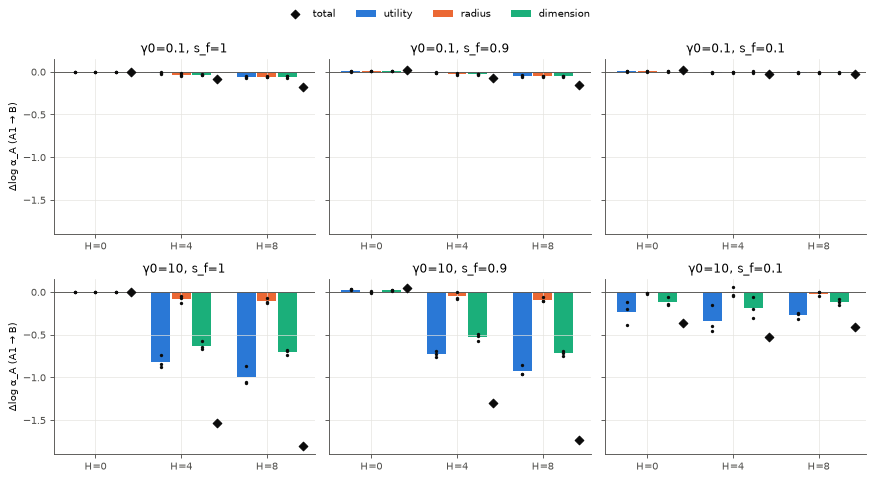

In [17]:
CH = [("utility", BLUE), ("radius", ORANGE), ("dimension", AQUA)]
if HAVE:
    fig, axes = plt.subplots(len(cfg.gammas), len(cfg.s_fs), figsize=(11, 6), sharey=True, squeeze=False)
    for i, g in enumerate(cfg.gammas):
        for j, sf in enumerate(cfg.s_fs):
            ax = axes[i, j]
            for k, h in enumerate(cfg.hammings):
                rs = sel(g, h, sf)
                if not rs: continue
                for ci, (ch, col) in enumerate(CH):
                    v = [r["backward"]["A1_to_B"][ch] for r in rs]; x = k + (ci - 1) * 0.24
                    ax.bar(x, np.mean(v), width=0.22, color=col, label=ch if (i, j, k) == (0, 0, 0) else None)
                    ax.scatter([x] * len(v), v, s=9, color=INK, zorder=3, linewidths=0)
                tot = [r["backward"]["A1_to_B"]["total"] for r in rs]
                ax.scatter([k + 0.42], [np.mean(tot)], marker="D", s=30, color=INK, zorder=4,
                           label="total" if (i, j, k) == (0, 0, 0) else None)
            ax.axhline(0, color=MUTED, linewidth=0.8)
            ax.set_xticks(range(len(cfg.hammings)), [f"H={h}" for h in cfg.hammings])
            ax.set_title(f"γ0={g:g}, s_f={sf:g}")
        axes[i, 0].set_ylabel("Δlog α_A (A1 → B)")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
    plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

**Q2. Behavioural forgetting and relearning.** Test loss on A through A → B → A, seed 0, s_f = 0.9. Each phase is scaled to unit width, because the step counts differ by orders of magnitude across γ₀.

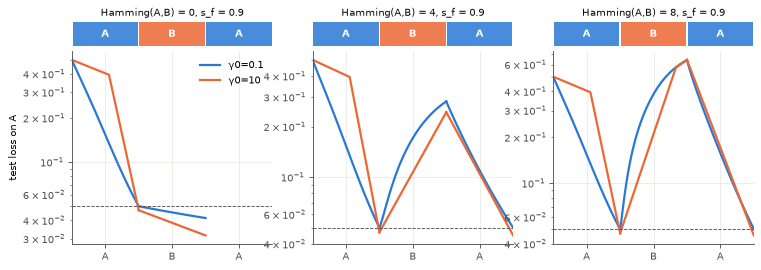

| γ0 | s_f | H | n | forgetting on B, test loss (vs running min) | forgetting on B, test acc (vs running max) | savings log((1+steps A1)/(1+steps A2)) | savings per seed | raw steps A1 (per seed) | raw steps B | raw steps A2 |
|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 3 | +0.0000 | +0.0000 | +7.456 | +7.38 +7.42 +7.57 | 1610/1660/1935 | 0/0/0 | 0/0/0 |
| 0.1 | 1 | 4 | 3 | +0.2798 | +0.2500 | +0.568 | +0.41 +0.72 +0.57 | 1610/1660/1935 | 1543/1240/1653 | 1067/807/1091 |
| 0.1 | 1 | 8 | 3 | +0.6988 | +0.4971 | +0.192 | +0.13 +0.21 +0.24 | 1610/1660/1935 | 1997/1710/1754 | 1408/1352/1525 |
| 0.1 | 0.9 | 0 | 3 | -0.0002 | +0.0000 | +7.456 | +7.38 +7.42 +7.57 | 1610/1660/1935 | 176/227/348 | 0/0/0 |
| 0.1 | 0.9 | 4 | 3 | +0.2318 | +0.2433 | +0.679 | +0.45 +0.78 +0.80 | 1610/1660/1935 | 1525/1379/1565 | 1024/761/865 |
| 0.1 | 0.9 | 8 | 3 | +0.5432 | +0.4758 | +0.379 | +0.30 +0.41 +0.42 | 1610/1660/1935 | 1918/1606/1547 | 1187/1102/1266 |
| 0.1 | 0.1 | 0 | 3 | +0.0211 | +0.0079 | +2.204 | +1.86 +2.70 +2.05 | 1610/1660/1935 | 1601/1273/1486 | 250/111/247 |
| 0.1 | 0.1 | 4 | 3 | +0.0476 | +0.0283 | +1.405 | +1.60 +1.39 +1.23 | 1610/1660/1935 | 1669/1454/1819 | 325/413/566 |
| 0.1 | 0.1 | 8 | 3 | +0.0365 | +0.0062 | +1.588 | +1.47 +1.59 +1.70 | 1610/1660/1935 | 1430/1696/1422 | 369/338/351 |
| 10 | 1 | 0 | 3 | +0.0000 | +0.0000 | +3.876 | +3.83 +3.83 +3.97 | 45/45/52 | 0/0/0 | 0/0/0 |
| 10 | 1 | 4 | 3 | +0.2616 | +0.2500 | +1.090 | +0.88 +1.19 +1.20 | 45/45/52 | 25/19/20 | 18/13/15 |
| 10 | 1 | 8 | 3 | +0.7077 | +0.5000 | +0.435 | +0.27 +0.46 +0.57 | 45/45/52 | 38/38/29 | 34/28/29 |
| 10 | 0.9 | 0 | 3 | -0.0137 | +0.0000 | +3.876 | +3.83 +3.83 +3.97 | 45/45/52 | 3/2/4 | 0/0/0 |
| 10 | 0.9 | 4 | 3 | +0.2185 | +0.2433 | +1.454 | +1.26 +1.53 +1.57 | 45/45/52 | 23/20/21 | 12/9/10 |
| 10 | 0.9 | 8 | 3 | +0.5611 | +0.4875 | +1.105 | +1.00 +1.06 +1.26 | 45/45/52 | 30/28/23 | 16/15/14 |
| 10 | 0.1 | 0 | 3 | +0.0072 | +0.0100 | +3.414 | +3.14 +3.83 +3.28 | 45/45/52 | 22/16/20 | 1/0/1 |
| 10 | 0.1 | 4 | 3 | +0.0228 | +0.0133 | +2.742 | +3.14 +2.73 +2.36 | 45/45/52 | 20/21/25 | 1/2/4 |
| 10 | 0.1 | 8 | 3 | +0.0183 | +0.0021 | +2.952 | +2.44 +3.83 +2.58 | 45/45/52 | 22/24/21 | 3/0/3 |

In [18]:
if HAVE:
    SF = 0.9 if 0.9 in cfg.s_fs else cfg.s_fs[0]
    fig = plt.figure(figsize=(11, 3.6))
    gs = fig.add_gridspec(2, len(cfg.hammings), height_ratios=[0.12, 1], hspace=0.05)
    for k, h in enumerate(cfg.hammings):
        stream_strip(fig.add_subplot(gs[0, k]), h, SF)
        ax = fig.add_subplot(gs[1, k])
        for g in cfg.gammas:
            rs = sel(g, h, SF)
            r = next((x for x in rs if x["spec"]["seed"] == 0), None)
            if r is None: continue
            for p, ph in enumerate(("A1", "B", "A2")):
                rec = r["trajectory"][ph]; st = np.array([q["step"] for q in rec], float)
                x = p + (st / st.max() if st.max() > 0 else np.zeros_like(st))
                ax.plot(x, [q["A_test_loss"] for q in rec], color=GAMMA_COL[g], label=f"γ0={g:g}" if p == 0 else None)
        ax.axhline(cfg.target_loss, color=MUTED, linewidth=0.8, linestyle="--")
        ax.set_yscale("log"); ax.set_xlim(0, 3); ax.set_xticks([0.5, 1.5, 2.5], ["A", "B", "A"])
        if k == 0: ax.set_ylabel("test loss on A"); ax.legend(frameon=False)
    plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                fl = [r["behaviour"]["forget_B_loss"]["forgetting"] for r in rs]
                fa = [r["behaviour"]["forget_B_acc"]["forgetting"] for r in rs]
                sv = [r["behaviour"]["savings"] for r in rs]
                stp = lambda p: "/".join(str(r["behaviour"]["steps"][p]) for r in rs)
                rows.append([f"{g:g}", f"{sf:g}", h, len(rs), f"{np.mean(fl):+.4f}", f"{np.mean(fa):+.4f}", f"{np.mean(sv):+.3f}",
                             " ".join(f"{x:+.2f}" for x in sv), stp("A1"), stp("B"), stp("A2")])
    md_table(["γ0", "s_f", "H", "n", "forgetting on B, test loss (vs running min)", "forgetting on B, test acc (vs running max)",
              "savings log((1+steps A1)/(1+steps A2))", "savings per seed", "raw steps A1 (per seed)", "raw steps B", "raw steps A2"], rows)

**Q3. Forward transfer.** Does the geometric change A made on B's manifolds (specific = Δlog α_{y_B} − Δlog α_{y\*}, from init to after A) go with behavioural forward transfer (FT_beh = log((1+steps fresh)/(1+steps B)))? Hamming 0 with s_f 1.0 is excluded. Panels are stratified by s_f; nothing is pooled.

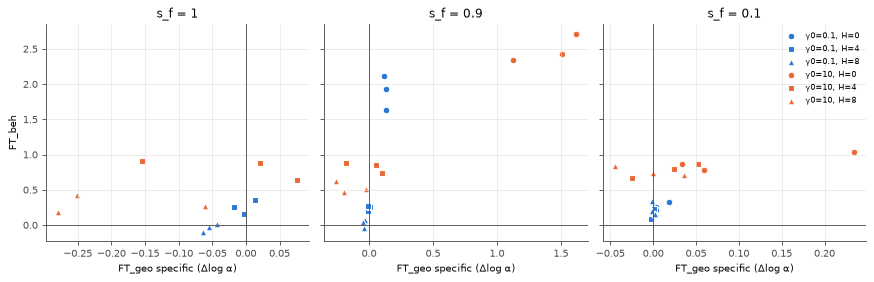

| γ0 | s_f | H | Δlog α_{y_B} total | utility | radius | dimension | Δlog α_{y*} | specific | FT_beh | zero-shot loss on B | raw steps B (per seed) | raw steps fresh B |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 4 | +0.059 | +0.006 | +0.023 | +0.030 | +0.061 | -0.002 | +0.254 | 0.448 | 1543/1240/1653 | 1800/1775/2123 |
| 0.1 | 1 | 8 | +0.007 | -0.004 | +0.005 | +0.006 | +0.061 | -0.054 | -0.035 | 0.834 | 1997/1710/1754 | 2031/1661/1599 |
| 0.1 | 0.9 | 0 | +0.173 | +0.053 | +0.055 | +0.065 | +0.045 | +0.127 | +1.890 | 0.068 | 176/227/348 | 1470/1561/1777 |
| 0.1 | 0.9 | 4 | +0.044 | +0.007 | +0.018 | +0.020 | +0.045 | -0.002 | +0.240 | 0.464 | 1525/1379/1565 | 1848/1792/2045 |
| 0.1 | 0.9 | 8 | +0.007 | -0.005 | +0.007 | +0.005 | +0.045 | -0.038 | +0.021 | 0.787 | 1918/1606/1547 | 2058/1669/1476 |
| 0.1 | 0.1 | 0 | +0.009 | +0.005 | +0.003 | +0.002 | +0.001 | +0.008 | +0.261 | 0.421 | 1601/1273/1486 | 2057/1753/1840 |
| 0.1 | 0.1 | 4 | +0.000 | +0.000 | +0.000 | -0.001 | +0.001 | -0.001 | +0.169 | 0.517 | 1669/1454/1819 | 2024/1816/1992 |
| 0.1 | 0.1 | 8 | +0.001 | -0.001 | -0.000 | +0.001 | +0.001 | -0.000 | +0.227 | 0.505 | 1430/1696/1422 | 1732/1970/1999 |
| 10 | 1 | 4 | +0.464 | +0.023 | +0.114 | +0.327 | +0.483 | -0.019 | +0.805 | 0.432 | 25/19/20 | 48/47/51 |
| 10 | 1 | 8 | +0.286 | -0.072 | +0.110 | +0.248 | +0.483 | -0.197 | +0.294 | 0.809 | 38/38/29 | 50/46/45 |
| 10 | 0.9 | 0 | +1.804 | +0.786 | +0.122 | +0.896 | +0.388 | +1.416 | +2.490 | 0.068 | 3/2/4 | 44/44/51 |
| 10 | 0.9 | 4 | +0.377 | -0.000 | +0.102 | +0.276 | +0.388 | -0.011 | +0.820 | 0.435 | 23/20/21 | 49/48/52 |
| 10 | 0.9 | 8 | +0.231 | -0.076 | +0.081 | +0.226 | +0.388 | -0.157 | +0.536 | 0.758 | 30/28/23 | 51/45/44 |
| 10 | 0.1 | 0 | +0.085 | -0.021 | +0.039 | +0.067 | -0.025 | +0.109 | +0.894 | 0.419 | 22/16/20 | 49/47/49 |
| 10 | 0.1 | 4 | -0.007 | -0.035 | -0.003 | +0.031 | -0.025 | +0.018 | +0.781 | 0.498 | 20/21/25 | 49/48/50 |
| 10 | 0.1 | 8 | -0.028 | -0.046 | -0.012 | +0.031 | -0.025 | -0.003 | +0.763 | 0.504 | 22/24/21 | 47/50/50 |

In [19]:
MARK = dict(zip(cfg.hammings, ["o", "s", "^", "v", "P"]))
if HAVE:
    fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.6), sharey=True)
    for ax, sf in zip(axes, cfg.s_fs):
        for g in cfg.gammas:
            for h in cfg.hammings:
                if h == 0 and sf == 1.0: continue
                rs = sel(g, h, sf)
                ax.scatter([r["forward"]["specific"] for r in rs], [r["behaviour"]["FT_beh"] for r in rs],
                           color=GAMMA_COL[g], marker=MARK[h], s=36, edgecolors="white", linewidths=1,
                           label=f"γ0={g:g}, H={h}" if sf == cfg.s_fs[-1] else None)
        ax.axhline(0, color=MUTED, linewidth=0.8); ax.axvline(0, color=MUTED, linewidth=0.8)
        ax.set_title(f"s_f = {sf:g}"); ax.set_xlabel("FT_geo specific (Δlog α)")
    axes[0].set_ylabel("FT_beh"); axes[-1].legend(frameon=False, fontsize=7, loc="best"); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs or (h == 0 and sf == 1.0): continue
                f = lambda k: np.mean([r["forward"]["total"][k] for r in rs])
                rows.append([f"{g:g}", f"{sf:g}", h, f"{f('total'):+.3f}", f"{f('utility'):+.3f}", f"{f('radius'):+.3f}",
                             f"{f('dimension'):+.3f}", f"{np.mean([r['forward']['ystar'] for r in rs]):+.3f}",
                             f"{np.mean([r['forward']['specific'] for r in rs]):+.3f}", f"{np.mean([r['behaviour']['FT_beh'] for r in rs]):+.3f}",
                             f"{np.mean([r['behaviour']['first_loss']['B'] for r in rs]):.3f}",
                             "/".join(str(r["behaviour"]["steps"]["B"]) for r in rs),
                             "/".join(str(r["behaviour"]["steps"]["freshB"]) for r in rs)])
    md_table(["γ0", "s_f", "H", "Δlog α_{y_B} total", "utility", "radius", "dimension", "Δlog α_{y*}", "specific", "FT_beh",
              "zero-shot loss on B", "raw steps B (per seed)", "raw steps fresh B"], rows)

**Q4. Richness by phase.** Means over cells and seeds for each γ₀. ΔK and ΔK_u are relative to init, on A's fixed probe set. r_t is the weight change within a phase.

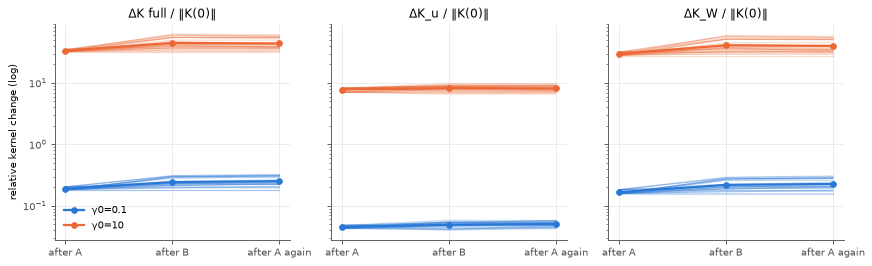

| γ0 | after | weight change from init | r_t (this phase) | ΔK full | ΔK_u | ΔK_W | ‖K_W‖/‖K‖ | CKA(K, y_A y_Aᵀ) | CKA(K_B, y_B y_Bᵀ) |
|---|---|---|---|---|---|---|---|---|---|
| 0.1 | A1 | 0.02 | 0.02 | 0.19 | 0.0453 | 0.167 | 0.149 | +0.267 | +0.218 |
| 0.1 | B | 0.0324 | 0.0259 | 0.244 | 0.0492 | 0.219 | 0.190 | +0.244 | +0.261 |
| 0.1 | A2 | 0.0306 | 0.0132 | 0.252 | 0.0508 | 0.228 | 0.195 | +0.265 | +0.242 |
| 10 | A1 | 0.615 | 0.615 | 33.5 | 7.81 | 29.7 | 0.870 | +0.355 | +0.236 |
| 10 | B | 0.739 | 0.402 | 44.9 | 8.25 | 41 | 0.897 | +0.275 | +0.317 |
| 10 | A2 | 0.734 | 0.19 | 44 | 8.15 | 40.2 | 0.896 | +0.321 | +0.276 |

In [20]:
if HAVE:
    PH = ("A1", "B", "A2")
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
    for ax, (k, lab) in zip(axes, [("dK_full", "ΔK full"), ("dK_u", "ΔK_u"), ("dK_W", "ΔK_W")]):
        for g in cfg.gammas:
            rs = sel(g)
            per = np.array([[r["richness"][ph][k] for ph in PH] for r in rs])
            for row in per:
                ax.plot(range(3), row, color=GAMMA_COL[g], alpha=0.25, linewidth=1)
            ax.plot(range(3), per.mean(0), color=GAMMA_COL[g], marker="o", markersize=5, label=f"γ0={g:g}")
        ax.set_yscale("log"); ax.set_xticks(range(3), ["after A", "after B", "after A again"]); ax.set_title(f"{lab} / ‖K(0)‖")
    axes[0].set_ylabel("relative kernel change (log)"); axes[0].legend(frameon=False); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        rs = sel(g)
        for ph in PH:
            m = lambda k: np.mean([r["richness"][ph][k] for r in rs])
            rows.append([f"{g:g}", ph, f"{m('weight_change'):.3g}", f"{np.mean([r['richness']['r_t'][ph] for r in rs]):.3g}",
                         f"{m('dK_full'):.3g}", f"{m('dK_u'):.3g}", f"{m('dK_W'):.3g}", f"{m('KW_share'):.3f}",
                         f"{m('cka_K_yA'):+.3f}", f"{m('cka_K_yB'):+.3f}"])
    md_table(["γ0", "after", "weight change from init", "r_t (this phase)", "ΔK full", "ΔK_u", "ΔK_W", "‖K_W‖/‖K‖",
              "CKA(K, y_A y_Aᵀ)", "CKA(K_B, y_B y_Bᵀ)"], rows)

**Q5. Centre correlation ρ_c on A's manifolds, signed and absolute (`glue` convention), by boundary.**

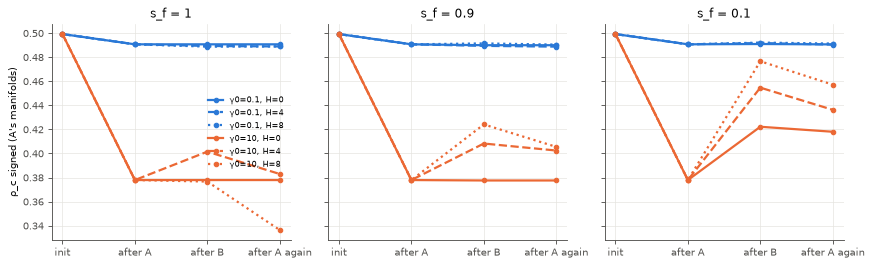

| γ0 | s_f | H | init (signed / glue) | after A | after B | after A again |
|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | +0.499 / 0.599 | +0.491 / 0.547 | +0.491 / 0.547 | +0.491 / 0.547 |
| 0.1 | 1 | 4 | +0.499 / 0.599 | +0.491 / 0.547 | +0.489 / 0.568 | +0.489 / 0.535 |
| 0.1 | 1 | 8 | +0.499 / 0.599 | +0.491 / 0.547 | +0.489 / 0.605 | +0.489 / 0.535 |
| 0.1 | 0.9 | 0 | +0.499 / 0.599 | +0.491 / 0.547 | +0.490 / 0.543 | +0.490 / 0.543 |
| 0.1 | 0.9 | 4 | +0.499 / 0.599 | +0.491 / 0.547 | +0.489 / 0.564 | +0.489 / 0.533 |
| 0.1 | 0.9 | 8 | +0.499 / 0.599 | +0.491 / 0.547 | +0.491 / 0.599 | +0.490 / 0.543 |
| 0.1 | 0.1 | 0 | +0.499 / 0.599 | +0.491 / 0.547 | +0.491 / 0.542 | +0.491 / 0.537 |
| 0.1 | 0.1 | 4 | +0.499 / 0.599 | +0.491 / 0.547 | +0.492 / 0.556 | +0.490 / 0.544 |
| 0.1 | 0.1 | 8 | +0.499 / 0.599 | +0.491 / 0.547 | +0.492 / 0.557 | +0.491 / 0.552 |
| 10 | 1 | 0 | +0.499 / 0.599 | +0.378 / 0.203 | +0.378 / 0.203 | +0.378 / 0.203 |
| 10 | 1 | 4 | +0.499 / 0.599 | +0.378 / 0.203 | +0.401 / 2.51 | +0.383 / 0.22 |
| 10 | 1 | 8 | +0.499 / 0.599 | +0.378 / 0.203 | +0.377 / 3.78 | +0.336 / 0.211 |
| 10 | 0.9 | 0 | +0.499 / 0.599 | +0.378 / 0.203 | +0.378 / 0.207 | +0.378 / 0.207 |
| 10 | 0.9 | 4 | +0.499 / 0.599 | +0.378 / 0.203 | +0.408 / 1.79 | +0.402 / 0.275 |
| 10 | 0.9 | 8 | +0.499 / 0.599 | +0.378 / 0.203 | +0.424 / 3.2 | +0.405 / 0.266 |
| 10 | 0.1 | 0 | +0.499 / 0.599 | +0.378 / 0.203 | +0.422 / 0.382 | +0.418 / 0.358 |
| 10 | 0.1 | 4 | +0.499 / 0.599 | +0.378 / 0.203 | +0.455 / 0.555 | +0.436 / 0.373 |
| 10 | 0.1 | 8 | +0.499 / 0.599 | +0.378 / 0.203 | +0.477 / 0.483 | +0.457 / 0.39 |

In [21]:
BND = ("A@init", "A@A1", "A@B", "A@A2")
LSTYLE = dict(zip(cfg.hammings, ["-", "--", ":", "-."]))
if HAVE:
    fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.4), sharey=True)
    for ax, sf in zip(axes, cfg.s_fs):
        for g in cfg.gammas:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                ax.plot(range(4), [np.mean([r["geometry"][b]["rho_c_signed"] for r in rs]) for b in BND],
                        color=GAMMA_COL[g], linestyle=LSTYLE[h], marker="o", markersize=4,
                        label=f"γ0={g:g}, H={h}" if sf == cfg.s_fs[0] else None)
        ax.set_xticks(range(4), ["init", "after A", "after B", "after A again"]); ax.set_title(f"s_f = {sf:g}")
    axes[0].set_ylabel("ρ_c signed (A's manifolds)"); axes[0].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                cell = []
                for b in ("A@init", "A@A1", "A@B", "A@A2"):
                    cell.append(f"{np.mean([r['geometry'][b]['rho_c_signed'] for r in rs]):+.3f} / "
                                f"{np.mean([r['geometry'][b]['rho_c_glue'] for r in rs]):.3g}")
                rows.append([f"{g:g}", f"{sf:g}", h] + cell)
    md_table(["γ0", "s_f", "H", "init (signed / glue)", "after A", "after B", "after A again"], rows)

## 7. Expectation readings

Each expectation is quoted verbatim from the cell written before the run and read by
the rule fixed there.

In [22]:
EXP = {1: "forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1",
       2: "at γ0 = 10, the utility channel carries most of Δlog α_A",
       3: "Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain)",
       4: "Hamming 4 and 8 are similar (cliff, not dose)",
       5: "K_u change separates γ0 more cleanly than the full NTK change"}
G_LO, G_HI = cfg.gammas
FL = {g: FLOORS[g]["floor"] for g in cfg.gammas}
d_AB = lambda r: r["backward"]["A1_to_B"]
def by_seed(g, h, sf, f=lambda r: d_AB(r)["total"]):
    return {r["spec"]["seed"]: f(r) for r in sel(g, h, sf)}
def fmt(rv): return f"{rv['mean']:+.4f} [{rv['lo']:+.4f}, {rv['hi']:+.4f}] n={rv['n']}"
READ = []
if HAVE:
    for sf in cfg.s_fs:                                   # 1
        a, b = by_seed(G_HI, 8, sf), by_seed(G_LO, 8, sf)
        d = [a[s] - b[s] for s in sorted(set(a) & set(b))]
        fl = max(FL.values()); rv = resolve(d, fl)
        v = "held" if rv["sign"] < 0 else "not held" if rv["sign"] > 0 else "unresolved at floor"
        READ.append([1, f"s_f={sf:g}", f"d = Δ(γ0={G_HI:g}) − Δ(γ0={G_LO:g}) at H8: {fmt(rv)}", f"{fl:.4f}", v])
    cells2 = [(h, sf) for h in cfg.hammings if h > 0 for sf in cfg.s_fs] + [(0, sf) for sf in cfg.s_fs if sf < 1.0]
    for h, sf in cells2:                                  # 2
        rs = sel(G_HI, h, sf); tot = [d_AB(r)["total"] for r in rs]; ut = [d_AB(r)["utility"] for r in rs]
        rv = resolve(tot, FL[G_HI]); frac = np.mean(ut) / np.mean(tot)
        v = ("held" if frac > 0.5 else "not held") if rv["resolved"] else "unresolved at floor"
        READ.append([2, f"γ0={G_HI:g}, H={h}, s_f={sf:g}", f"total {fmt(rv)}; utility fraction {frac:+.3f}", f"{FL[G_HI]:.4f}", v])
    for g in cfg.gammas:                                  # 3
        rv = resolve(list(by_seed(g, 0, 0.9).values()), FL[g])
        v = "held" if rv["sign"] > 0 else "not held" if rv["sign"] < 0 else "unresolved at floor"
        READ.append([3, f"γ0={g:g}", f"Δlog α_A at H0, s_f 0.9: {fmt(rv)}", f"{FL[g]:.4f}", v])
    for g in cfg.gammas:                                  # 4
        for sf in cfg.s_fs:
            a, b = by_seed(g, 8, sf), by_seed(g, 4, sf)
            d = [a[s] - b[s] for s in sorted(set(a) & set(b))]
            rv = resolve(d, FL[g])
            if rv["lo"] > -2 * FL[g] and rv["hi"] < 2 * FL[g]: v = "held"
            elif rv["resolved"]: v = "not held"
            else: v = "unresolved at floor"
            READ.append([4, f"γ0={g:g}, s_f={sf:g}", f"d = Δ(H8) − Δ(H4): {fmt(rv)}; equivalence band ±{2 * FL[g]:.4f}", f"{FL[g]:.4f}", v])
    uniq = {}                                             # 5: phase A is identical across cells, so use unique (seed, γ0)
    for r in arms:
        uniq[(r["spec"]["seed"], r["spec"]["gamma"])] = r["richness"]["A1"]
    def dprime(k):
        lo = np.log([v[k] for (s, g), v in uniq.items() if g == G_LO]); hi = np.log([v[k] for (s, g), v in uniq.items() if g == G_HI])
        sp = math.sqrt((lo.var(ddof=1) + hi.var(ddof=1)) / 2)
        return (hi.mean() - lo.mean()) / sp, float(np.exp(lo).mean()), float(np.exp(hi).mean())
    du, dfu = dprime("dK_u"), dprime("dK_full")
    v = "held" if du[0] > dfu[0] else "not held"
    READ.append([5, "after A, unique (seed, γ0)",
                 f"d′(ΔK_u) = {du[0]:.1f} vs d′(ΔK full) = {dfu[0]:.1f}; lazy ΔK_u = {du[1]:.4f}, lazy ΔK full = {dfu[1]:.4f}; "
                 f"rich ΔK_u = {du[2]:.3g}, rich ΔK full = {dfu[2]:.3g}", "—", v])
    md_table(["#", "expectation (verbatim)", "stratum", "statistic (mean [95% CI])", "floor", "reading"],
             [[i, EXP[i], st, stat, fl, f"**{v}**"] for i, st, stat, fl, v in READ])

| # | expectation (verbatim) | stratum | statistic (mean [95% CI]) | floor | reading |
|---|---|---|---|---|---|
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=1 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -1.6321 [-1.9189, -1.3454] n=3 | 0.0829 | **held** |
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=0.9 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -1.5758 [-1.8640, -1.2876] n=3 | 0.0829 | **held** |
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=0.1 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -0.3833 [-0.5375, -0.2291] n=3 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=1 | total -1.5322 [-1.8441, -1.2202] n=3; utility fraction +0.535 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=0.9 | total -1.3029 [-1.3899, -1.2158] n=3; utility fraction +0.560 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=0.1 | total -0.5320 [-1.1560, +0.0920] n=3; utility fraction +0.632 | 0.0829 | **unresolved at floor** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=1 | total -1.8059 [-2.0880, -1.5239] n=3; utility fraction +0.552 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=0.9 | total -1.7314 [-2.0260, -1.4368] n=3; utility fraction +0.532 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=0.1 | total -0.4139 [-0.6015, -0.2263] n=3; utility fraction +0.663 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=0, s_f=0.9 | total +0.0448 [-0.0022, +0.0917] n=3; utility fraction +0.607 | 0.0829 | **unresolved at floor** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=0, s_f=0.1 | total -0.3659 [-0.7720, +0.0401] n=3; utility fraction +0.636 | 0.0829 | **unresolved at floor** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=0.1 | Δlog α_A at H0, s_f 0.9: +0.0211 [+0.0074, +0.0349] n=3 | 0.0448 | **unresolved at floor** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=10 | Δlog α_A at H0, s_f 0.9: +0.0448 [-0.0022, +0.0917] n=3 | 0.0829 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=1 | d = Δ(H8) − Δ(H4): -0.0878 [-0.1079, -0.0678] n=3; equivalence band ±0.0896 | 0.0448 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.0870 [-0.1179, -0.0561] n=3; equivalence band ±0.0896 | 0.0448 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=0.1 | d = Δ(H8) − Δ(H4): -0.0104 [-0.1073, +0.0866] n=3; equivalence band ±0.0896 | 0.0448 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=1 | d = Δ(H8) − Δ(H4): -0.2737 [-0.5141, -0.0334] n=3; equivalence band ±0.1657 | 0.0829 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.4285 [-0.6480, -0.2090] n=3; equivalence band ±0.1657 | 0.0829 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=0.1 | d = Δ(H8) − Δ(H4): +0.1181 [-0.6557, +0.8920] n=3; equivalence band ±0.1657 | 0.0829 | **unresolved at floor** |
| 5 | K_u change separates γ0 more cleanly than the full NTK change | after A, unique (seed, γ0) | d′(ΔK_u) = 72.6 vs d′(ΔK full) = 98.9; lazy ΔK_u = 0.0453, lazy ΔK full = 0.1901; rich ΔK_u = 7.81, rich ΔK full = 33.5 | — | **not held** |

### Observations (n = 3, not claims)

Written 2026-11-08 after reading the QUICK grid (commit `52f5567`, clean stamps,
`aba_lib` hash `0cb635a8b44814ad`). Floors: 0.045 at γ₀ = 0.1 and 0.083 at γ₀ = 10
(trained representation); the init floor is 0.037. Nothing here is a finding until a
pre-commit names its reading.

1. **Geometric forgetting depends on γ₀, but behavioural forgetting does not.**
   After B, A's retained capacity falls far more at γ₀ = 10 than at γ₀ = 0.1. At
   Hamming 4–8 under frozen or drifting input, Δlog α_A is −1.3 to −1.8 at γ₀ = 10
   and −0.07 to −0.17 at γ₀ = 0.1. Forgetting in test loss on A is nearly the same
   for both γ₀ (H4 frozen: 0.28 vs 0.26; H8 frozen: 0.70 vs 0.71). Behavioural
   forgetting is set by the label relation; the geometric damage is set by richness.
2. **The channel split at γ₀ = 10 is utility first, dimension close behind.** The
   utility fraction is 0.53–0.66 where the total is resolved. Dimension carries most
   of the rest, and radius is small.
3. **Jump input (s_f 0.1) mutes forgetting.** Forgetting in both measures is
   smaller than under frozen or drift at the same Hamming distance. Relearning is
   fast: savings are positive in every cell.
4. **Hamming 0 under drift shows a small positive Δlog α_A** at both γ₀ (+0.02 and
   +0.04). Neither clears 2 floors at n = 3. Forward transfer in that cell is large
   at both γ₀: FT_beh is +1.9 and +2.5, and the specific FT_geo at γ₀ = 10 is +1.4.
5. **At Hamming 8 under frozen or drifting input, the specific FT_geo is negative at
   γ₀ = 10 (−0.20 and −0.16), but FT_beh is positive (+0.29 and +0.54).** A rich learner trained on A reaches criterion
   on B faster than a fresh learner, even though the geometry prepared by A is worse
   for y_B than for the held-out y\*. The behavioural and geometric forward measures
   disagree in sign here.
6. **The full NTK change at γ₀ = 0.1 is mostly K_W growth.** Lazy ΔK_u = 0.045 ≪ 1,
   and lazy ΔK full = 0.19 is driven by ΔK_W = 0.17, which grows from zero with the
   readout. The full NTK still separates γ₀ more cleanly than K_u (d′ 99 vs 73),
   because K_W grows about 180× from lazy to rich, against about 170× for K_u.
7. **ρ_c (`glue`, unnormalised) jumps 9–19× after B at γ₀ = 10** (Hamming 4–8,
   frozen or drift) and returns after relearning A. The signed, normalised ρ_c moves
   by at most 0.05. The jump is in anchor norm, not direction.